# 12 · Explore and clean reported crime (NYPD complaints)
**Know Before You Rent · Team BUTA**

**Datasets**
- [NYPD Complaint Data Historic](https://data.cityofnewyork.us/d/qgea-i56i): through last year.
- [NYPD Complaint Data Current (Year To Date)](https://data.cityofnewyork.us/d/5uac-w243): this year.

Both are downloaded from 2022 onward. **One row = one crime reported to the NYPD**, with offense, severity (felony, misdemeanor or violation), date and location.

**Role in the project:** neighborhood context for a renter ("how much crime is reported around this building?") and a candidate model feature (the `crime_` group in notebook 10).

**Responsible use**
- We **do not download** the suspect and victim demographic columns.
- Reported crime also reflects where police patrol and who calls 911, so it is not a pure measure of danger.
- For privacy, NYPD places reports at the middle of the street segment, not the exact address. That's why we count crime within **200 m**, not 100 m.

In [1]:
import sys, pathlib, json
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import config, housing as H, clean_housing as C, features_housing as F
from src.preprocess import CleaningReport
from src.plots import save, ACCENT, MUTED

pd.set_option("display.float_format", "{:,.2f}".format)
raw = pd.concat([H.load("crime_historic"), H.load("crime_current")], ignore_index=True)
print(f"{len(raw):,} reported crimes (historic: {H.monthly_rows('crime_historic').sum():,}, "
      f"current year: {H.monthly_rows('crime_current').sum():,})")
H.overview(raw)

2,670,820 reported crimes (historic: 2,243,782, current year: 427,038)


,missing_%,distinct,example
cmplnt_num,0.00,2670818,239889607
cmplnt_fr_dt,0.00,5184,2022-01-30T00:00:00.000
rpt_dt,0.00,1734,2022-01-30T00:00:00.000
ky_cd,0.00,69,578
ofns_desc,0.00,68,HARRASSMENT 2
law_cat_cd,0.00,3,VIOLATION
crm_atpt_cptd_cd,0.00,2,COMPLETED
boro_nm,0.00,6,QUEENS
addr_pct_cd,0.00,78,105
loc_of_occur_desc,0.00,6,INSIDE


## 1. Volume, severity and offense types

In [2]:
raw["rpt_dt"] = pd.to_datetime(raw["rpt_dt"].astype(str), errors="coerce")
display(pd.crosstab(raw["rpt_dt"].dt.year, raw["law_cat_cd"]))
raw["ofns_desc"].value_counts().head(20).to_frame("reports")

law_cat_cd,FELONY,MISDEMEANOR,VIOLATION
rpt_dt,,,
2022,178952,268998,84046
2023,186740,282419,85958
2024,188418,299929,88761
2025,188142,299832,91587
2026,136006,222182,68850


,reports
ofns_desc,
PETIT LARCENY,516770
HARRASSMENT 2,404211
ASSAULT 3 & RELATED OFFENSES,283395
GRAND LARCENY,232831
CRIMINAL MISCHIEF & RELATED OF,188222
FELONY ASSAULT,136135
VEHICLE AND TRAFFIC LAWS,107292
MISCELLANEOUS PENAL LAW,87273
OFF. AGNST PUB ORD SENSBLTY &,85509


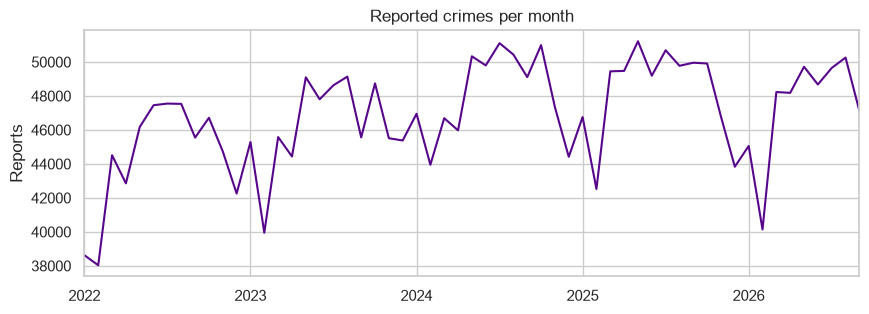

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.2))
raw.groupby(raw["rpt_dt"].dt.to_period("M")).size().plot(ax=ax, color=ACCENT)
ax.set(title="Reported crimes per month", xlabel="", ylabel="Reports")
save(fig, "rent12a_crime_per_month")

## 2. Data quality: locations

In [4]:
lat = pd.to_numeric(raw["latitude"], errors="coerce")
print(f"Missing coordinates: {lat.isna().mean():.1%} | zero coordinates: {(lat == 0).mean():.1%}")
print(f"Duplicate report ids: {raw['cmplnt_num'].duplicated().sum():,}")
raw["prem_typ_desc"].value_counts().head(10).to_frame("reports by premises")

Missing coordinates: 0.0% | zero coordinates: 0.0%


Duplicate report ids: 2


,reports by premises
prem_typ_desc,
STREET,789372
RESIDENCE - APT. HOUSE,577706
RESIDENCE-HOUSE,237706
RESIDENCE - PUBLIC HOUSING,167938
CHAIN STORE,138608
TRANSIT - NYC SUBWAY,109463
DEPARTMENT STORE,61766
COMMERCIAL BUILDING,53151
OTHER,49422


## 3. Clean

In [5]:
rep = CleaningReport("crime")
crime = C.clean_crime(raw, rep)
display(pd.DataFrame(rep.steps)[["step", "rows_before", "rows_after", "rows_removed", "detail"]])
display(pd.Series(C.CRIME_GROUPS, name="regex pattern").to_frame())
pd.crosstab(crime["crime_group"], crime["severity"], margins=True).sort_values("All", ascending=False)

,step,rows_before,rows_after,rows_removed,detail
0,load_raw,2670820,2670820,0,historic + current year
1,drop_duplicate_cmplnt_num,2670820,2670818,2,
2,parse_dates,2670818,2670818,0,missing or pre-2022 rpt_dt
3,valid_coordinates,2670818,2670769,49,"missing, zero or outside-NYC coordinates"
4,derive_fields,2670769,2670769,0,"severity, crime group (regex), in-residence flag"


,regex pattern
violent,MURDER|HOMICIDE|RAPE|SEX CRIME|ROBBERY|FELONY ...
property,BURGLARY|LARCENY|THEFT|STOLEN|CRIMINAL MISCHIE...
drugs/weapons,DANGEROUS DRUGS|DANGEROUS WEAPONS|CANNABIS|MAR...
harassment,HARR?ASS?MENT|MENACING|OFF\. AGNST PUB ORD


severity,FELONY,MISDEMEANOR,VIOLATION,All
crime_group,,,,
All,878227,1373342,419200,2670769
property,490313,705773,0,1196086
violent,228902,322324,0,551226
harassment,0,85509,404210,489719
other,97209,210439,14670,322318
drugs/weapons,61803,49297,320,111420


In [6]:
# Spot-check the regex groups
crime.groupby("crime_group")["ofns_desc"].agg(lambda s: s.value_counts().head(4).index.tolist()).to_frame("top offenses")

,top offenses
crime_group,
drugs/weapons,['DANGEROUS DRUGS' 'DANGEROUS WEAPONS' 'CANNAB...
harassment,['HARRASSMENT 2' 'OFF. AGNST PUB ORD SENSBLTY &']
other,['VEHICLE AND TRAFFIC LAWS' 'MISCELLANEOUS PEN...
property,['PETIT LARCENY' 'GRAND LARCENY' 'CRIMINAL MIS...
violent,['ASSAULT 3 & RELATED OFFENSES' 'FELONY ASSAUL...


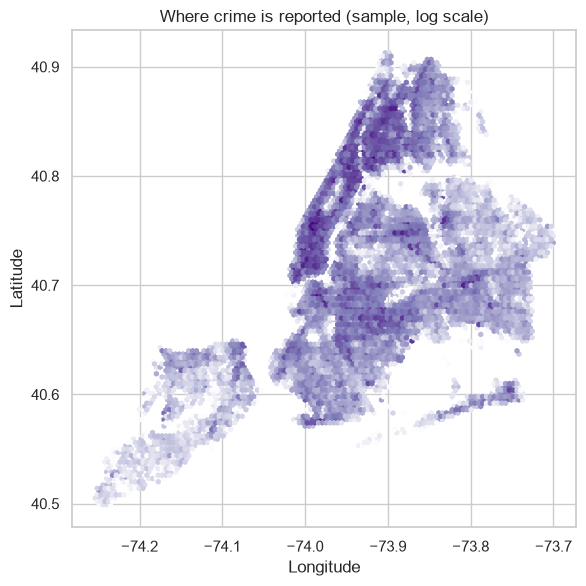

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 7))
sample = crime.sample(min(300_000, len(crime)), random_state=0)
hb = ax.hexbin(sample["longitude"], sample["latitude"], gridsize=120, bins="log", cmap="Purples", mincnt=1)
ax.set_aspect(1 / np.cos(np.radians(40.7)))
ax.set(title="Where crime is reported (sample, log scale)", xlabel="Longitude", ylabel="Latitude")
save(fig, "rent12b_crime_map")

## 4. Crime around residential buildings (within 200 m)

In [8]:
inp = F.load_inputs() | {"crime": crime}
universe = F.building_universe(inp["pluto"], inp["landlords"])
around = F.crime_counts(universe, crime, [2024, 2025])
around.describe(percentiles=[.25, .5, .75, .9]).T

,count,mean,std,min,25%,50%,75%,90%,max
crime_total,"172,546.00",194.86,176.17,0.00,76.50,140.50,255.00,412.00,"2,810.50"
crime_felony,"172,546.00",64.82,54.07,0.00,27.00,49.00,86.00,134.50,899.50
crime_in_residence,"172,546.00",72.42,61.92,0.00,30.00,54.00,92.50,156.00,671.00
crime_violent,"172,546.00",42.08,46.81,0.00,13.00,27.00,54.00,94.50,609.00
crime_property,"172,546.00",85.02,97.12,0.00,34.00,56.00,101.50,169.50,"2,275.50"
crime_drugs_weapons,"172,546.00",9.27,19.71,0.00,1.00,3.00,9.00,22.50,466.00
crime_harassment,"172,546.00",34.85,27.88,0.00,15.00,26.50,46.00,74.00,231.50


In [9]:
# Is crime nearby related to housing problems? (rank correlation with complaints per apartment, 2024-25)
snap = pd.read_parquet(str(F.FEATURES_FILE).format(year=2025))
rate = (snap["c_total"] / snap["unitsres"]).rank()
around.rank().corrwith(rate).rename("Spearman ρ with complaints per apartment").to_frame()

,Spearman ρ with complaints per apartment
crime_total,0.28
crime_felony,0.28
crime_in_residence,0.29
crime_violent,0.27
crime_property,0.25
crime_drugs_weapons,0.24
crime_harassment,0.30


## 5. Save

In [10]:
crime.to_parquet(C.OUT["crime"], index=False)
(config.REPORTS_DIR / "cleaning_report_crime.json").write_text(json.dumps(rep.to_dict(), indent=2, default=str))
print(f"Saved {len(crime):,} rows → {C.OUT['crime'].relative_to(ROOT)}")

Saved 2,670,769 rows → data/processed/crime_clean.parquet


**Takeaways**
- About 99% of reports have usable coordinates, so crime can be counted around every building.
- Counts within 200 m vary hugely between buildings. That makes it useful context for a renter.
- Its link to *housing* problems is modest. In notebook 10 we test whether it adds predictive power beyond history, landlord and the 100 m neighborhood. If it doesn't, it stays in the report as context only.

→ Rerun **notebook 09** and **notebook 10** to include the crime features.